In [14]:
%load_ext autoreload
%autoreload 2

import sys
import importlib
from pathlib import Path
import cv2
import numpy as np
import torch
# Resolve paths
PROJECT_ROOT = Path("..").resolve()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

# Import pipeline classes and utilities
from dataset import ImageDataset
from feature_matching import FeatureMatcher
from pose_estimation import PoseEstimator
from triangulation import Triangulator
from bundle_adjustment import BundleAdjuster
from utils import build_intrinsic_matrix, export_ply, initialize_seed_submodel, register_submodel_cameras, umeyama_sim3, align_and_merge
from feature_tracks import TrackGraph
import itertools
import open3d as o3d
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
# 1. Load Dataset
dataset = ImageDataset()
print(f"Loaded {len(dataset)} images.")

# 2. Build Intrinsic Matrix K
height, width = dataset[0].shape[:2]
K = build_intrinsic_matrix(width=width, height=height)

# 3. Instantiate Pipeline Modules
matcher = FeatureMatcher()
estimator = PoseEstimator(K)
triangulator = Triangulator(K)
optimizer = BundleAdjuster(K)
track_graph = TrackGraph()

Loaded 177 images.


In [16]:
# 1. Pre-extract features for the entire dataset
all_kp, all_des = {}, {}
print(f"Extracting features for all {len(dataset)} images...")
for i in range(len(dataset)):
    kp, des = matcher.extract_features(dataset[i])
    all_kp[i], all_des[i] = kp, des

# 2. Push to GPU VRAM
print("Pushing all descriptors to GPU VRAM...")
all_des_gpu = {
    i: torch.tensor(des, dtype=torch.float32, device="cuda") 
    for i, des in all_des.items()
}

# 3. Build Forward Match Graph
match_graph = {}
print("Building exhaustive Match Graph across all camera pairs...")
for i, j in itertools.combinations(range(len(dataset)), 2):
    # This automatically includes Lowe's ratio test on the GPU
    good_matches = matcher.match_and_filter_gpu(all_des_gpu[i], all_des_gpu[j])
    if len(good_matches) >= 15:
        match_graph[(i, j)] = good_matches

print(f"Match Graph complete. Found {len(match_graph)} valid overlapping image pairs.")

Extracting features for all 177 images...
Pushing all descriptors to GPU VRAM...
Building exhaustive Match Graph across all camera pairs...
Match Graph complete. Found 15549 valid overlapping image pairs.


In [17]:
# Front Facade Sub-Model
cams_front, track_front = initialize_seed_submodel(
    (14, 15), estimator, triangulator, optimizer, all_kp, all_des, match_graph, TrackGraph
)

# Back Facade Sub-Model
cams_back, track_back = initialize_seed_submodel(
    (79, 80), estimator, triangulator, optimizer, all_kp, all_des, match_graph, TrackGraph
)

# Left Side Sub-Model
cams_left, track_left = initialize_seed_submodel(
    (0, 1), estimator, triangulator, optimizer, all_kp, all_des, match_graph, TrackGraph
)

# Right Side Sub-Model
cams_right, track_right = initialize_seed_submodel(
    (24, 25), estimator, triangulator, optimizer, all_kp, all_des, match_graph, TrackGraph
)

Sub-Model (14, 15) Initialized: 1424 points | RMSE: 0.2398 px
Sub-Model (79, 80) Initialized: 1182 points | RMSE: 0.3240 px
Sub-Model (0, 1) Initialized: 509 points | RMSE: 0.2657 px
Sub-Model (24, 25) Initialized: 750 points | RMSE: 0.2551 px


In [18]:
# --- Front Facade Sub-Model ---
cams_front, track_front = register_submodel_cameras(
    cams_front, track_front, range(len(dataset)), all_kp, all_des, match_graph, K, estimator, triangulator, optimizer
)

# --- Back Facade Sub-Model ---
cams_back, track_back = register_submodel_cameras(
    cams_back, track_back, range(len(dataset)), all_kp, all_des, match_graph, K, estimator, triangulator, optimizer
)

# --- Left Side Sub-Model ---
cams_left, track_left = register_submodel_cameras(
    cams_left, track_left, range(len(dataset)), all_kp, all_des, match_graph, K, estimator, triangulator, optimizer
)

# --- Right Side Sub-Model ---
cams_right, track_right = register_submodel_cameras(
    cams_right, track_right, range(len(dataset)), all_kp, all_des, match_graph, K, estimator, triangulator, optimizer
)

Pass 1 complete: Registered 64 cameras (Total in Sub-Model: 66).
Pass 2 complete: Registered 14 cameras (Total in Sub-Model: 80).
Pass 3 complete: Registered 9 cameras (Total in Sub-Model: 89).
Pass 1 complete: Registered 24 cameras (Total in Sub-Model: 26).
Pass 2 complete: Registered 16 cameras (Total in Sub-Model: 42).
Pass 3 complete: Registered 33 cameras (Total in Sub-Model: 75).
Pass 1 complete: Registered 9 cameras (Total in Sub-Model: 11).
Pass 2 complete: Registered 25 cameras (Total in Sub-Model: 36).
Pass 3 complete: Registered 13 cameras (Total in Sub-Model: 49).
Pass 1 complete: Registered 25 cameras (Total in Sub-Model: 27).
Pass 2 complete: Registered 14 cameras (Total in Sub-Model: 41).
Pass 3 complete: Registered 19 cameras (Total in Sub-Model: 60).


In [19]:
# 1. Extract (N, 3) array from Track Graph dictionary
front_point_cloud = np.array(list(track_front.global_points3D.values()), dtype=np.float32)
back_point_cloud = np.array(list(track_back.global_points3D.values()), dtype=np.float32)
left_point_cloud = np.array(list(track_left.global_points3D.values()), dtype=np.float32)
right_point_cloud = np.array(list(track_right.global_points3D.values()), dtype=np.float32)


# 2. Export to PLY file
output_path = PROJECT_ROOT / "outputs" / "incremental_building_reconstruction_front.ply"
output_path.parent.mkdir(parents=True, exist_ok=True)
export_ply(str(output_path), front_point_cloud)
print(f"Successfully exported {len(front_point_cloud)} 3D points to {output_path}")

output_path = PROJECT_ROOT / "outputs" / "incremental_building_reconstruction_back.ply"
output_path.parent.mkdir(parents=True, exist_ok=True)
export_ply(str(output_path), back_point_cloud)
print(f"Successfully exported {len(back_point_cloud)} 3D points to {output_path}")

output_path = PROJECT_ROOT / "outputs" / "incremental_building_reconstruction_left.ply"
output_path.parent.mkdir(parents=True, exist_ok=True)
export_ply(str(output_path), left_point_cloud)
print(f"Successfully exported {len(left_point_cloud)} 3D points to {output_path}")

output_path = PROJECT_ROOT / "outputs" / "incremental_building_reconstruction_right.ply"
output_path.parent.mkdir(parents=True, exist_ok=True)
export_ply(str(output_path), right_point_cloud)
print(f"Successfully exported {len(right_point_cloud)} 3D points to {output_path}")

Successfully exported 75585 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction_front.ply
Successfully exported 75585 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction_front.ply
Successfully exported 59016 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction_back.ply
Successfully exported 59016 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction_back.ply
Successfully exported 39166 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction_left.ply
Successfully exported 39166 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction_left.ply
Successfully exported 52797 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction_right.ply
Successfully exported 52

Cleaned Point Cloud: Reduced from 75585 to 72627 points.


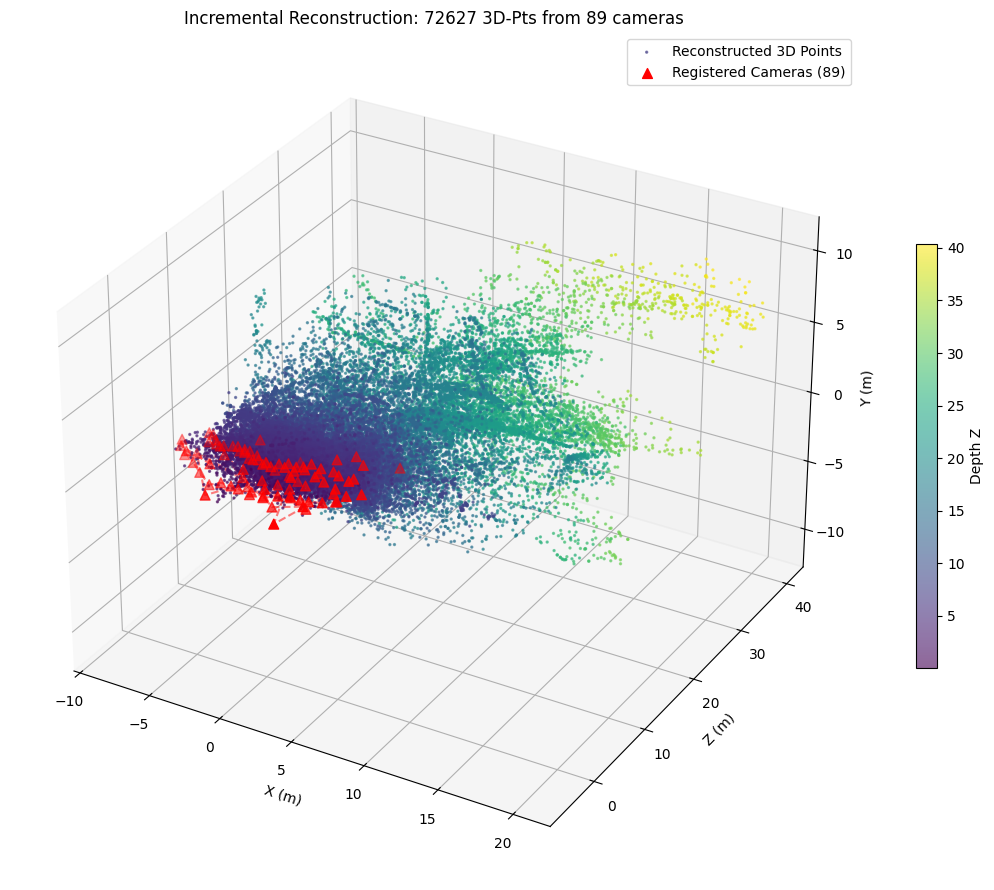

Successfully exported 72627 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/front_final_reconstruction.ply
Gereinigtes 3D-Modell erfolgreich gespeichert unter: /home/semi/projects/propyläen_3d_reconstruct/outputs/front_final_reconstruction.ply


In [20]:
# 1. Clean Point Cloud (Remove Wild Distance Outliers)
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(front_point_cloud)

# Filter out points whose distance is beyond 2 standard deviations
clean_pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=50, std_ratio=2.0)
clean_points = np.asarray(clean_pcd.points)

print(
    f"Cleaned Point Cloud: Reduced from {len(front_point_cloud)} to"
    f" {len(clean_points)} points."
)

# 2. 3D Plot of Cleaned Point Cloud and Registered Cameras

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Visualizing 3D point cloud (farblich nach Tiefe Z codiert)
scatter = ax.scatter(
    clean_points[:, 0],
    clean_points[:, 2],
    clean_points[:, 1],
    c=clean_points[:, 2],
    cmap="viridis",
    s=2,
    alpha=0.6,
    label="Reconstructed 3D Points",
)

# Plotting C = -R^T * T)
cam_centers = []
for idx, cam_data in cams_front.items():
  R_c = cam_data["R"]
  T_c = cam_data["T"]
  C = (-R_c.T @ T_c).ravel()
  cam_centers.append(C)

cam_centers = np.array(cam_centers)

# Cameras
ax.scatter(
    cam_centers[:, 0],
    cam_centers[:, 2],
    cam_centers[:, 1],
    c="red",
    s=50,
    marker="^",
    label=f"Registered Cameras ({len(cam_centers)})",
)

# Trajectory of camera pos
ax.plot(
    cam_centers[:, 0],
    cam_centers[:, 2],
    cam_centers[:, 1],
    c="red",
    linestyle="--",
    alpha=0.5,
)

# Axes
ax.set_xlabel("X (m)")
ax.set_ylabel("Z (m)")
ax.set_zlabel("Y (m)")
ax.set_title(
    f"Incremental Reconstruction: {len(clean_points)} 3D-Pts from"
    f" {len(cams_front)} cameras"
)
ax.legend()
fig.colorbar(scatter, ax=ax, shrink=0.5, label="Depth Z")

plt.tight_layout()
plt.show()

# 3. Export Cleaned Pointcloud as PLY File
output_file = PROJECT_ROOT / "outputs" / "front_final_reconstruction.ply"
output_file.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_file), clean_points)
print(f"Gereinigtes 3D-Modell erfolgreich gespeichert unter: {output_file}")

Cleaned Point Cloud: Reduced from 59016 to 56776 points.


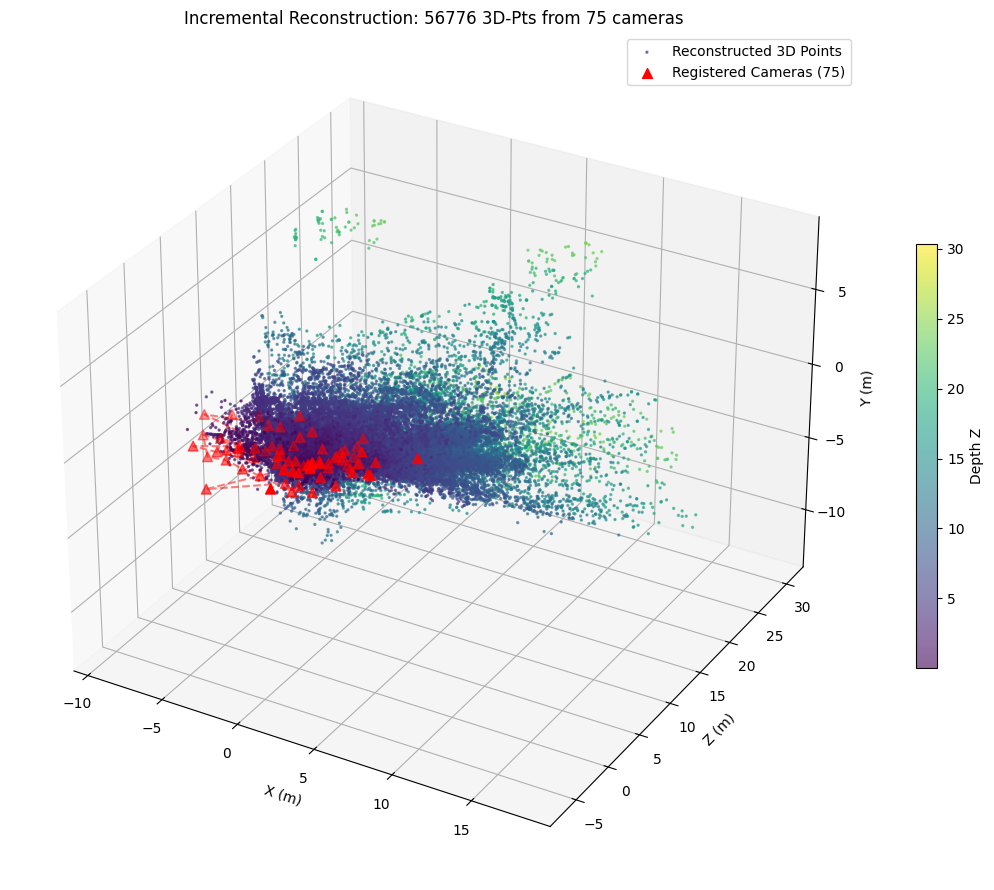

Successfully exported 56776 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/back_final_reconstruction.ply
Gereinigtes 3D-Modell erfolgreich gespeichert unter: /home/semi/projects/propyläen_3d_reconstruct/outputs/back_final_reconstruction.ply


In [21]:
# 1. Clean Point Cloud (Remove Wild Distance Outliers)
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(back_point_cloud)

# Filter out points whose distance is beyond 2 standard deviations
clean_pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=50, std_ratio=2.0)
clean_points = np.asarray(clean_pcd.points)

print(
    f"Cleaned Point Cloud: Reduced from {len(back_point_cloud)} to"
    f" {len(clean_points)} points."
)

# 2. 3D Plot of Cleaned Point Cloud and Registered Cameras

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Visualize 3D point cloud (farblich nach Tiefe Z codiert)
scatter = ax.scatter(
    clean_points[:, 0],
    clean_points[:, 2],
    clean_points[:, 1],
    c=clean_points[:, 2],
    cmap="viridis",
    s=2,
    alpha=0.6,
    label="Reconstructed 3D Points",
)

# Plotting C = -R^T * T)
cam_centers = []
for idx, cam_data in cams_back.items():
  R_c = cam_data["R"]
  T_c = cam_data["T"]
  C = (-R_c.T @ T_c).ravel()
  cam_centers.append(C)

cam_centers = np.array(cam_centers)

# Cameras
ax.scatter(
    cam_centers[:, 0],
    cam_centers[:, 2],
    cam_centers[:, 1],
    c="red",
    s=50,
    marker="^",
    label=f"Registered Cameras ({len(cam_centers)})",
)

# Trajectory of camera pos
ax.plot(
    cam_centers[:, 0],
    cam_centers[:, 2],
    cam_centers[:, 1],
    c="red",
    linestyle="--",
    alpha=0.5,
)

# Axes
ax.set_xlabel("X (m)")
ax.set_ylabel("Z (m)")
ax.set_zlabel("Y (m)")
ax.set_title(
    f"Incremental Reconstruction: {len(clean_points)} 3D-Pts from"
    f" {len(cams_back)} cameras"
)
ax.legend()
fig.colorbar(scatter, ax=ax, shrink=0.5, label="Depth Z")

plt.tight_layout()
plt.show()

# 3. Export Cleaned Pointcloud as PLY File
output_file = PROJECT_ROOT / "outputs" / "back_final_reconstruction.ply"
output_file.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_file), clean_points)
print(f"Gereinigtes 3D-Modell erfolgreich gespeichert unter: {output_file}")

Cleaned Point Cloud: Reduced from 39166 to 37446 points.


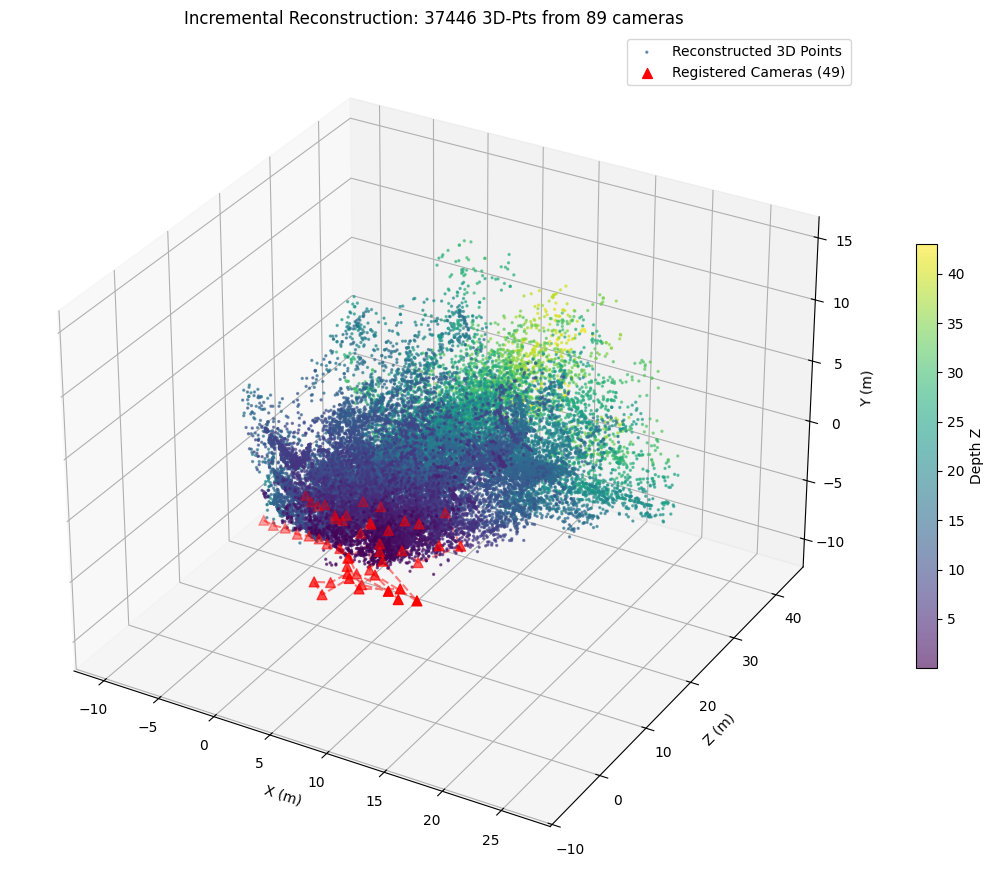

Successfully exported 37446 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/left_final_reconstruction.ply
Gereinigtes 3D-Modell erfolgreich gespeichert unter: /home/semi/projects/propyläen_3d_reconstruct/outputs/left_final_reconstruction.ply


In [22]:
# 1. Clean Point Cloud (Remove Wild Distance Outliers)
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(left_point_cloud)

# Filter out points whose distance is beyond 2 standard deviations
clean_pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=50, std_ratio=2.0)
clean_points = np.asarray(clean_pcd.points)

print(
    f"Cleaned Point Cloud: Reduced from {len(left_point_cloud)} to"
    f" {len(clean_points)} points."
)

# 2. 3D Plot of Cleaned Point Cloud and Registered Cameras

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Visualize 3D point cloud (farblich nach Tiefe Z codiert)
scatter = ax.scatter(
    clean_points[:, 0],
    clean_points[:, 2],
    clean_points[:, 1],
    c=clean_points[:, 2],
    cmap="viridis",
    s=2,
    alpha=0.6,
    label="Reconstructed 3D Points",
)

# Plotting C = -R^T * T)
cam_centers = []
for idx, cam_data in cams_left.items():
  R_c = cam_data["R"]
  T_c = cam_data["T"]
  C = (-R_c.T @ T_c).ravel()
  cam_centers.append(C)

cam_centers = np.array(cam_centers)

# Cameras
ax.scatter(
    cam_centers[:, 0],
    cam_centers[:, 2],
    cam_centers[:, 1],
    c="red",
    s=50,
    marker="^",
    label=f"Registered Cameras ({len(cam_centers)})",
)

# Trajectory of camera pos
ax.plot(
    cam_centers[:, 0],
    cam_centers[:, 2],
    cam_centers[:, 1],
    c="red",
    linestyle="--",
    alpha=0.5,
)

# Axes
ax.set_xlabel("X (m)")
ax.set_ylabel("Z (m)")
ax.set_zlabel("Y (m)")
ax.set_title(
    f"Incremental Reconstruction: {len(clean_points)} 3D-Pts from"
    f" {len(cams_front)} cameras"
)
ax.legend()
fig.colorbar(scatter, ax=ax, shrink=0.5, label="Depth Z")

plt.tight_layout()
plt.show()

# 3. Export Cleaned Pointcloud as PLY File
output_file = PROJECT_ROOT / "outputs" / "left_final_reconstruction.ply"
output_file.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_file), clean_points)
print(f"Gereinigtes 3D-Modell erfolgreich gespeichert unter: {output_file}")

Cleaned Point Cloud: Reduced from 52797 to 51207 points.


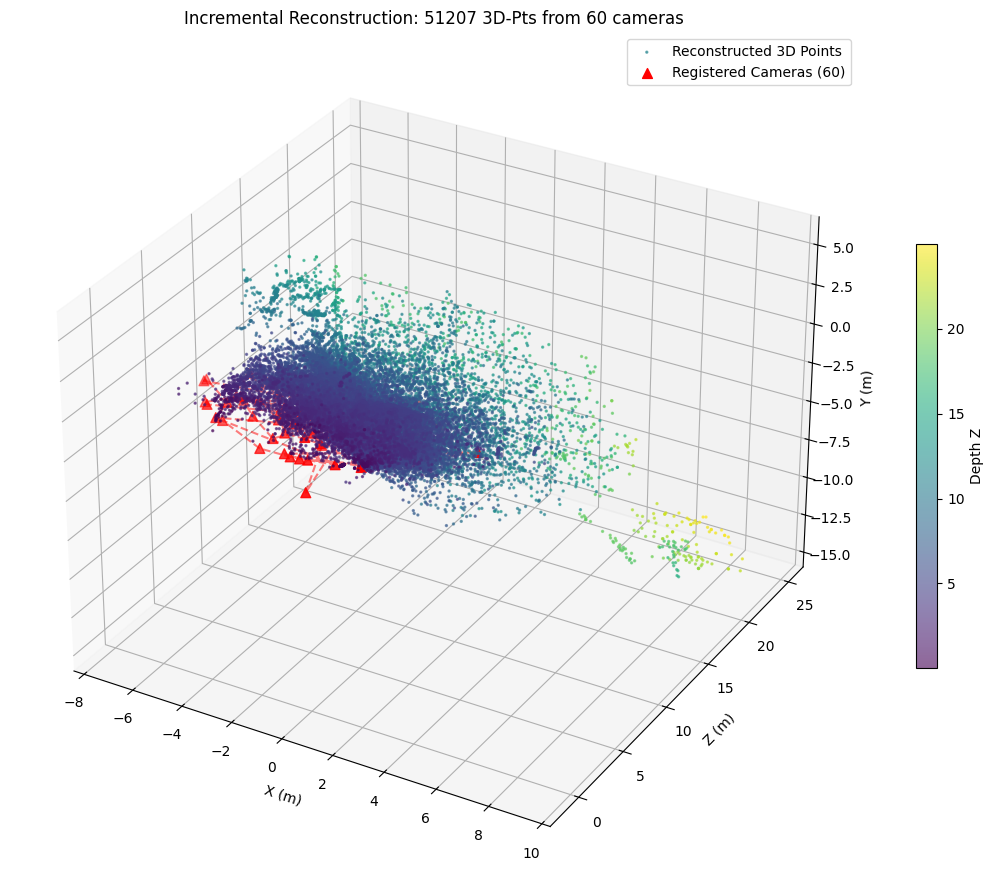

Successfully exported 51207 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/right_final_reconstruction.ply
Gereinigtes 3D-Modell erfolgreich gespeichert unter: /home/semi/projects/propyläen_3d_reconstruct/outputs/right_final_reconstruction.ply


In [23]:
# 1. Clean Point Cloud (Remove Wild Distance Outliers)
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(right_point_cloud)

# Filter out points whose distance is beyond 2 standard deviations
clean_pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=50, std_ratio=2.0)
clean_points = np.asarray(clean_pcd.points)

print(
    f"Cleaned Point Cloud: Reduced from {len(right_point_cloud)} to"
    f" {len(clean_points)} points."
)

# 2. 3D Plot of Cleaned Point Cloud and Registered Cameras

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Visualize 3D point cloud (farblich nach Tiefe Z codiert)
scatter = ax.scatter(
    clean_points[:, 0],
    clean_points[:, 2],
    clean_points[:, 1],
    c=clean_points[:, 2],
    cmap="viridis",
    s=2,
    alpha=0.6,
    label="Reconstructed 3D Points",
)

# Plotting C = -R^T * T)
cam_centers = []
for idx, cam_data in cams_right.items():
  R_c = cam_data["R"]
  T_c = cam_data["T"]
  C = (-R_c.T @ T_c).ravel()
  cam_centers.append(C)

cam_centers = np.array(cam_centers)

# Cameras
ax.scatter(
    cam_centers[:, 0],
    cam_centers[:, 2],
    cam_centers[:, 1],
    c="red",
    s=50,
    marker="^",
    label=f"Registered Cameras ({len(cam_centers)})",
)

# Trajectory of camera pos
ax.plot(
    cam_centers[:, 0],
    cam_centers[:, 2],
    cam_centers[:, 1],
    c="red",
    linestyle="--",
    alpha=0.5,
)

# Axes
ax.set_xlabel("X (m)")
ax.set_ylabel("Z (m)")
ax.set_zlabel("Y (m)")
ax.set_title(
    f"Incremental Reconstruction: {len(clean_points)} 3D-Pts from"
    f" {len(cams_right)} cameras"
)
ax.legend()
fig.colorbar(scatter, ax=ax, shrink=0.5, label="Depth Z")

plt.tight_layout()
plt.show()

# 3. Export Cleaned Pointcloud as PLY File
output_file = PROJECT_ROOT / "outputs" / "right_final_reconstruction.ply"
output_file.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_file), clean_points)
print(f"Gereinigtes 3D-Modell erfolgreich gespeichert unter: {output_file}")

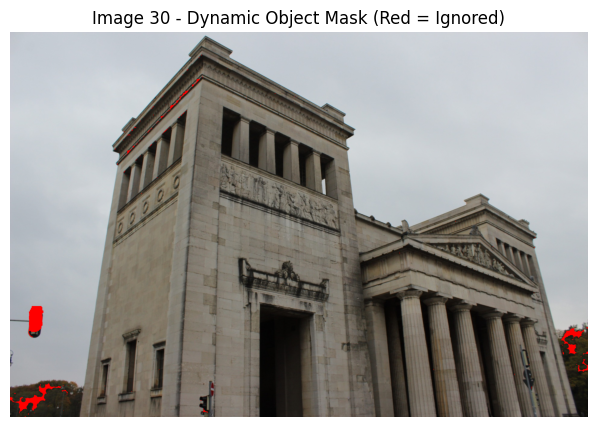

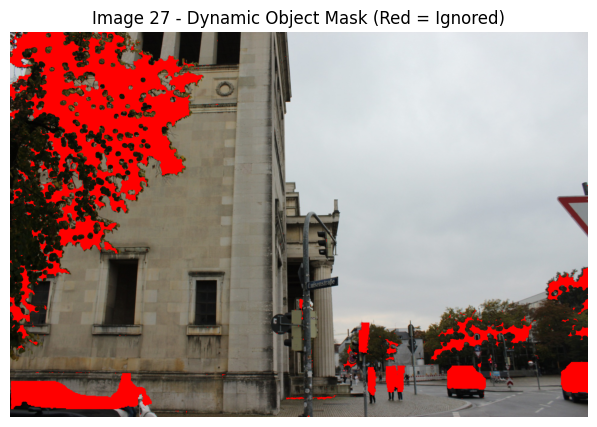

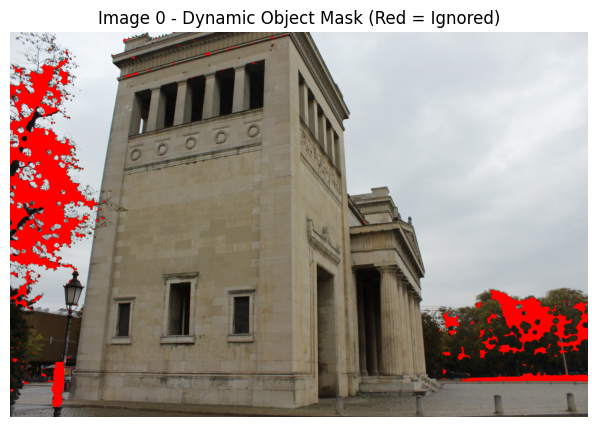

In [24]:
import cv2
import matplotlib.pyplot as plt

# Inspect mask on Image 0, Image 1, and Image 2
for idx in [30, 27, 0]:
    img = dataset[idx]
    mask = matcher.create_dynamic_mask(img)
    
    # Overlay mask on top of image (red overlay where masked out)
    overlay = img.copy()
    overlay[mask == 0] = [0, 0, 255]
    
    plt.figure(figsize=(10, 5))
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"Image {idx} - Dynamic Object Mask (Red = Ignored)")
    plt.axis("off")
    plt.show()